# Lab 2: Зниження розмірності, кластеризація та класифікація текстових даних

**Мета роботи:** ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів у Scikit-learn.


## Підготовка, ті самі дані, що й у Lab 1

In [10]:
import html
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

COLORS = {'benign': '#2a78d6', 'gafgyt': '#eb6834', 'mirai': '#1baf7a'}   

def clean_axes(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.grid(color='#e5e4e0', linewidth=0.8)
    ax.set_axisbelow(True)

In [11]:
DATA_DIR = Path("../detection+of+iot+botnet+attacks+n+baiot/Danmini_Doorbell")


def load_csv(path, category, label):
    part = pd.read_csv(path).copy()
    part['category'] = category
    part['label'] = label
    return part


parts = [load_csv(DATA_DIR / 'benign_traffic.csv', 'benign', 'benign')]
for f in sorted((DATA_DIR / 'gafgyt_attacks').rglob('*.csv')):
    parts.append(load_csv(f, 'gafgyt', 'gafgyt_' + f.stem))
for f in sorted((DATA_DIR / 'mirai_attacks').rglob('*.csv')):
    parts.append(load_csv(f, 'mirai', 'mirai_' + f.stem))

df = pd.concat(parts, ignore_index=True).drop_duplicates(ignore_index=True)
del parts

feature_cols = [c for c in df.columns if c not in ('category', 'label')]

le = LabelEncoder()
df['label_Encoded'] = le.fit_transform(df['label'])

print(f'Записів після видалення дублікатів: {len(df):,}')
print(f'Ознак: {len(feature_cols)}, класів: {df["label"].nunique()}')

Записів після видалення дублікатів: 996,539
Ознак: 115, класів: 11


In [12]:
N_PER_CLASS = 3000
df_bal = df.groupby('label').sample(n=N_PER_CLASS, random_state=42).reset_index(drop=True)

X = df_bal[feature_cols]
y = df_bal['label_Encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (26400, 115)  Test: (6600, 115)


## 1) Зниження розмірності та візуалізація даних

**PCA (Principal Component Analysis, метод головних компонент)** повертає систему координат так, щоб нові осі (**головні компоненти**) йшли вздовж напрямків, де дані найбільше розкидані (мають найбільшу дисперсію).


### Скільки компонент потрібно

Навчимо PCA з усіма компонентами на масштабованому train і подивимось, яку частку дисперсії пояснює кожна компонента (explained_variance_ratio_).

In [13]:
from sklearn.decomposition import PCA

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)

pca_full = PCA(random_state=42).fit(X_train_scaled)
evr = pca_full.explained_variance_ratio_     # частка дисперсії кожної компоненти
cum_evr = np.cumsum(evr)                     # накопичена частка

print(f'PC1 пояснює {evr[0]:.1%} дисперсії, PC2 - {evr[1]:.1%}, разом {cum_evr[1]:.1%}\n')
for share in (0.90, 0.95, 0.99):
    n = int(np.searchsorted(cum_evr, share) + 1)
    print(f'Щоб зберегти {share:.0%} дисперсії, потрібно {n:>2} компонент з {len(feature_cols)}')

PC1 пояснює 34.0% дисперсії, PC2 - 13.0%, разом 47.0%

Щоб зберегти 90% дисперсії, потрібно 11 компонент з 115
Щоб зберегти 95% дисперсії, потрібно 16 компонент з 115
Щоб зберегти 99% дисперсії, потрібно 25 компонент з 115


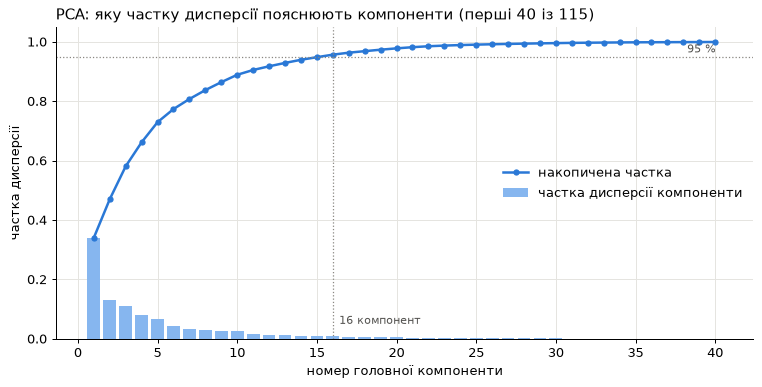

In [14]:
n_show = 40
n95 = int(np.searchsorted(cum_evr, 0.95) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=90)
ax.bar(range(1, n_show + 1), evr[:n_show], color='#86b6ef', label='частка дисперсії компоненти')
ax.plot(range(1, n_show + 1), cum_evr[:n_show], color='#2a78d6', marker='o', markersize=4,
        linewidth=2, label='накопичена частка')
ax.axhline(0.95, color='#898781', linestyle=':', linewidth=1)
ax.axvline(n95, color='#898781', linestyle=':', linewidth=1)
ax.text(n_show, 0.955, '95 %', ha='right', va='bottom', color='#52514e', fontsize=9)
ax.text(n95 + 0.4, 0.05, f'{n95} компонент', color='#52514e', fontsize=9)
ax.set_title('PCA: яку частку дисперсії пояснюють компоненти (перші 40 із 115)', loc='left', fontsize=12)
ax.set_xlabel('номер головної компоненти')
ax.set_ylabel('частка дисперсії')
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc='center right')
clean_axes(ax)
plt.show()

PC1 пояснює 34 % дисперсії, PC2 ще 13 %. Разом дві перші компоненти зберігають лише 47 % інформації, тому 2D-картинка PCA буде дуже спрощеною.

Накопичена крива швидко росте і виходить на плато. 90 % дисперсії дають 11 компонент, 95 % дають 16, а 99 % дають 25. Решта приблизно 90 компонент разом додають лише 1 %.

Отже, **115 ознак можна замінити на 16 компонент** (у 7 разів менше) і зберегти 95 % дисперсії. Це підтверджує сильну надлишковість ознак, яку ми бачили на heatmap кореляцій у Lab 1.

### Класифікація «до» і «після» PCA: kNN

Для порівняння беремо **kNN з k = 1**: це найкращий kNN з Lab 1 (accuracy 0.9947). kNN рахує відстані між точками, тому від кількості ознак у нього напряму залежить і якість, і швидкість.
Функція fit_eval навчає модель, рахує метрики на test і окремо заміряє час навчання (fit) і час передбачення (predict).

In [15]:
from sklearn.neighbors import KNeighborsClassifier


def fit_eval(name, model):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    t1 = time.perf_counter()
    y_pred = model.predict(X_test)
    t2 = time.perf_counter()

    n_features = model.named_steps['pca'].n_components_ if 'pca' in model.named_steps else X_train.shape[1]
    result = {
        'модель': name,
        'ознак': n_features,
        'accuracy': accuracy_score(y_test, y_pred),
        'macro F1': f1_score(y_test, y_pred, average='macro'),
        'помилок (з 6600)': int((y_pred != y_test).sum()),
        'час навчання, с': t1 - t0,
        'час передбачення, с': t2 - t1,
    }
    return result, y_pred


knn_plain = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=1)),
])
knn_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=1)),
])

res_plain, pred_plain = fit_eval('kNN без PCA', knn_plain)
res_pca, pred_pca = fit_eval('PCA(0.95) + kNN', knn_pca)

pd.DataFrame([res_plain, res_pca]).set_index('модель').round(4)

,ознак,accuracy,macro F1,помилок (з 6600),"час навчання, с","час передбачення, с"
модель,,,,,,
kNN без PCA,115,0.9947,0.9947,35,0.0655,0.3738
PCA(0.95) + kNN,16,0.9838,0.9838,107,0.0752,0.1721


Щоб зрозуміти, де саме з'явилися нові помилки, порівняємо найчастіші плутанини двох моделей.

In [16]:
def top_confusions(y_pred, n=5):
    cm = confusion_matrix(y_test, y_pred)
    pairs = [(le.classes_[i], le.classes_[j], cm[i, j])
             for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0]
    pairs = pd.DataFrame(pairs, columns=['справжній клас', 'передбачений клас', 'кількість'])
    return pairs.sort_values('кількість', ascending=False).head(n)


print('kNN без PCA:')
print(top_confusions(pred_plain).to_string(index=False))
print('\nPCA(0.95) + kNN:')
print(top_confusions(pred_pca).to_string(index=False))

kNN без PCA:
справжній клас передбачений клас  кількість
     mirai_ack         mirai_udp          8
     mirai_udp         mirai_ack          7
  gafgyt_combo       gafgyt_junk          6
   gafgyt_junk      gafgyt_combo          5
   gafgyt_scan            benign          3

PCA(0.95) + kNN:
справжній клас передбачений клас  кількість
  gafgyt_combo       gafgyt_junk         44
   gafgyt_junk      gafgyt_combo         31
     mirai_ack         mirai_udp         13
     mirai_udp         mirai_ack          8
   gafgyt_scan            benign          3


Після PCA **ознак стало у 7 разів менше**, 16 компонент замість 115. Якість трохи впала, accuracy знизилась з 0.9947 до 0.9838, а помилок стало 107 замість 35.

Майже всі нові помилки припадають на пару gafgyt_combo і gafgyt_junk, яку моделі плутали ще в Lab 1. Ці дві атаки відрізняються тонкими деталями, а такі деталі лежать у компонентах з малою дисперсією. Саме їх PCA і відкинув разом з останніми 5 % дисперсії.

Час навчання практично не змінився, бо kNN при fit лише запам'ятовує дані, а з PCA до цього додається ще навчання самого PCA. Зате передбачення стало приблизно вдвічі швидшим, бо kNN рахує відстані у 16-вимірному просторі замість 115-вимірного.

### Як кількість компонент впливає на якість і швидкість

Повторимо експеримент для різної кількості компонент, від 2 до 40, і для всіх 115 ознак.

In [17]:
rows = []
for n in [2, 5, 10, 16, 25, 40]:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n, random_state=42)),
        ('knn', KNeighborsClassifier(n_neighbors=1)),
    ])
    result, _ = fit_eval(f'PCA({n}) + kNN', model)
    result['збережено дисперсії'] = cum_evr[n - 1]
    rows.append(result)

res_plain['збережено дисперсії'] = 1.0
rows.append(res_plain)

sweep = pd.DataFrame(rows).set_index('модель')
sweep.round(4)

,ознак,accuracy,macro F1,помилок (з 6600),"час навчання, с","час передбачення, с",збережено дисперсії
модель,,,,,,,
PCA(2) + kNN,2,0.9115,0.9115,584,0.0761,0.0153,0.4698
PCA(5) + kNN,5,0.9574,0.9574,281,0.0748,0.0218,0.7292
PCA(10) + kNN,10,0.9771,0.9771,151,0.0905,0.0313,0.8888
PCA(16) + kNN,16,0.9838,0.9838,107,0.0613,0.1696,0.9565
PCA(25) + kNN,25,0.9926,0.9926,49,0.0776,0.2255,0.9903
PCA(40) + kNN,40,0.9932,0.9932,45,0.0777,0.2879,0.9991
kNN без PCA,115,0.9947,0.9947,35,0.0655,0.3738,1.0000


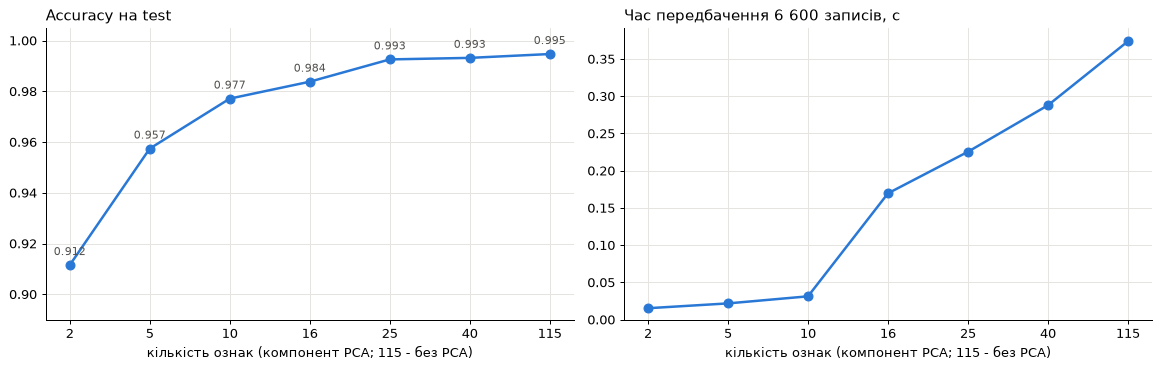

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), dpi=90)
x_labels = sweep['ознак'].astype(str)

axes[0].plot(x_labels, sweep['accuracy'], color='#2a78d6', marker='o', markersize=7, linewidth=2)
for x, v in zip(x_labels, sweep['accuracy']):
    axes[0].annotate(f'{v:.3f}', (x, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, color='#52514e')
axes[0].set_title('Accuracy на test', loc='left', fontsize=12)
axes[0].set_ylim(0.89, 1.005)

axes[1].plot(x_labels, sweep['час передбачення, с'], color='#2a78d6', marker='o', markersize=7, linewidth=2)
axes[1].set_title('Час передбачення 6 600 записів, с', loc='left', fontsize=12)
axes[1].set_ylim(bottom=0)

for ax in axes:
    ax.set_xlabel('кількість ознак (компонент PCA; 115 - без PCA)')
    clean_axes(ax)
plt.tight_layout()
plt.show()

Якість росте разом з кількістю компонент. 2 компоненти дають accuracy 0.91, 10 компонент дають 0.98, а 25 компонент (99 % дисперсії) дають 0.993, тобто майже як без PCA (0.995). Чим більше дисперсії збережено, тим менше втрачається дрібних відмінностей між класами.

Швидкість передбачення різко зростає, коли компонент 15 або менше. Справа не лише в кількості ознак. Параметр algorithm='auto' у kNN при такій кількості ознак будує **KD-дерево** і шукає сусідів без перебору всіх точок, а при більшій кількості рахує відстані до всіх точок train (brute force). Тому з 10 компонентами передбачення в рази швидше, ніж з 16.

Отже, 16 компонент (95 % дисперсії) втрачають 0.011 accuracy, але передбачають приблизно вдвічі швидше, а 25 компонент (99 %) працюють майже без втрат.

### Додатково: Random Forest «до» і «після» PCA

Для порівняння зробимо те саме з найкращою моделлю Lab 1 - Random Forest. Ліс не залежить від масштабу, тому без PCA навчаємо його на сирих ознаках, як у Lab 1.

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_plain = Pipeline([
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
])
rf_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
])

res_rf, pred_rf = fit_eval('Random Forest без PCA', rf_plain)
res_rf_pca, pred_rf_pca = fit_eval('PCA(0.95) + Random Forest', rf_pca)

print(top_confusions(pred_rf_pca, n=3).to_string(index=False))
pd.DataFrame([res_rf, res_rf_pca]).set_index('модель').round(4)

справжній клас передбачений клас  кількість
    gafgyt_udp        gafgyt_tcp        434
  gafgyt_combo       gafgyt_junk         32
   gafgyt_junk      gafgyt_combo         23


,ознак,accuracy,macro F1,помилок (з 6600),"час навчання, с","час передбачення, с"
модель,,,,,,
Random Forest без PCA,115,0.9995,0.9995,3,0.8540,0.0415
PCA(0.95) + Random Forest,16,0.9206,0.9106,524,0.9567,0.0447


Random Forest від PCA **сильно програє**, accuracy падає з 0.9995 до 0.92. Майже всі нові помилки однакові, це gafgyt_udp, передбачений як gafgyt_tcp.

У Lab 1 ми з'ясували, що tcp і udp розрізняються лише часовою міткою в ознаках HH_jit (артефакт даних), і ліс на сирих даних ставить поріг саме на цю мітку. Після масштабування й PCA ця різниця розмазується по компонентах і стає мізерною, тож записи tcp і udp опиняються майже в одній точці. kNN усе ще знаходить найближчого сусіда того самого класу (відстані до свого і чужого класу відрізняються приблизно на 10⁻⁷), а дерева ділять дані порогами по одній ознаці й таку крихітну різницю вже не ловлять.

Крім того, дерева добре працюють з початковими ознаками на зразок «кількість пакетів більша за N». Після PCA кожна компонента є сумішшю всіх ознак, і простих порогів стає менше. Через це час навчання лісу навіть зріс, бо деревам потрібно більше розбиттів.

Отже, PCA корисний не для всіх моделей. Він добре підходить методам, що працюють з відстанями (kNN, SVM), і часто шкодить деревам.

### Висновки щодо PCA

Для kNN якість трохи знизилась. Accuracy впала з 0.9947 до 0.9838 при збереженні 95 % дисперсії і до 0.9926 при 99 %. Втрачаються дрібні відмінності між схожими атаками gafgyt_combo і gafgyt_junk, які лежать у компонентах з малою дисперсією. Для Random Forest PCA шкодить сильно, accuracy падає з 0.9995 до 0.92.

Кількість ознак вдалося зменшити **зі 115 до 16 компонент** (у 7 разів) зі збереженням 95 % дисперсії або до 25 компонент (у 4.6 раза) зі збереженням 99 %. Це можливо, бо ознаки сильно корелюють між собою.

Для kNN навчання означає лише запам'ятовування даних, тому час fit майже не змінився, з PCA до нього додається тільки навчання самого PCA. Помітно змінився час передбачення, з 16 компонентами він приблизно вдвічі менший, а з 15 компонентами і менше менший у рази, бо kNN переходить на KD-дерево. Для Random Forest час навчання з PCA навіть зріс.

На цьому датасеті PCA дає великий виграш у компактності та швидкості kNN ціною невеликої втрати точності. Чи варто його застосовувати, залежить від задачі. Якщо важлива швидкість на великому потоці трафіку, 25 компонент будуть хорошим компромісом.

### Візуалізація у 2D за допомогою t-SNE

**t-SNE** (t-distributed Stochastic Neighbor Embedding) є нелінійним методом зниження розмірності, створеним саме для візуалізації.

Спочатку для кожної точки у вихідному просторі зі 115 ознак він рахує ймовірності того, що інші точки є її сусідами. Що ближче точка, то більша ймовірність (використовується гаусівський розподіл). Потім розкидає точки на площині і рахує такі самі ймовірності вже в 2D, але через t-розподіл Стьюдента з «важкими хвостами». Далі точки на площині рухаються, поки два набори ймовірностей не стануть максимально схожими, тобто мінімізується дивергенція Кульбака-Лейблера.

PCA є лінійною проєкцією і зберігає великі відстані (глобальну структуру), а t-SNE зберігає сусідство (локальну структуру). Близькі точки залишаються близькими, але відстані між далекими групами і розміри груп на картинці t-SNE нічого не означають. Також t-SNE не вміє перетворювати нові точки (немає методу transform), тому його використовують лише для візуалізації, а не як крок перед моделлю.

Параметр n_components=2 задає площину. perplexity=30 приблизно відповідає кількості сусідів, яку враховують для кожної точки (типові значення від 5 до 50). init='pca' бере початкове розташування точок з PCA, так результат стабільніший, а random_state=42 робить результат відтворюваним.

t-SNE працює повільно, його час росте швидше за кількість точок, тому беремо підвибірку по 500 записів на клас (5 500 точок). Для порівняння поруч побудуємо PCA-проєкцію на ті самі 2 компоненти.

In [20]:
from sklearn.manifold import TSNE

vis_df = df_bal.groupby('label').sample(n=500, random_state=42).reset_index(drop=True)
X_vis = StandardScaler().fit_transform(vis_df[feature_cols])

pca_2d = PCA(n_components=2, random_state=42).fit_transform(X_vis)

t0 = time.perf_counter()
tsne_2d = TSNE(n_components=2, perplexity=30, init='pca', random_state=42).fit_transform(X_vis)
print(f'Точок: {len(vis_df):,}. t-SNE рахувався {time.perf_counter() - t0:.0f} с')

Точок: 5,500. t-SNE рахувався 10 с


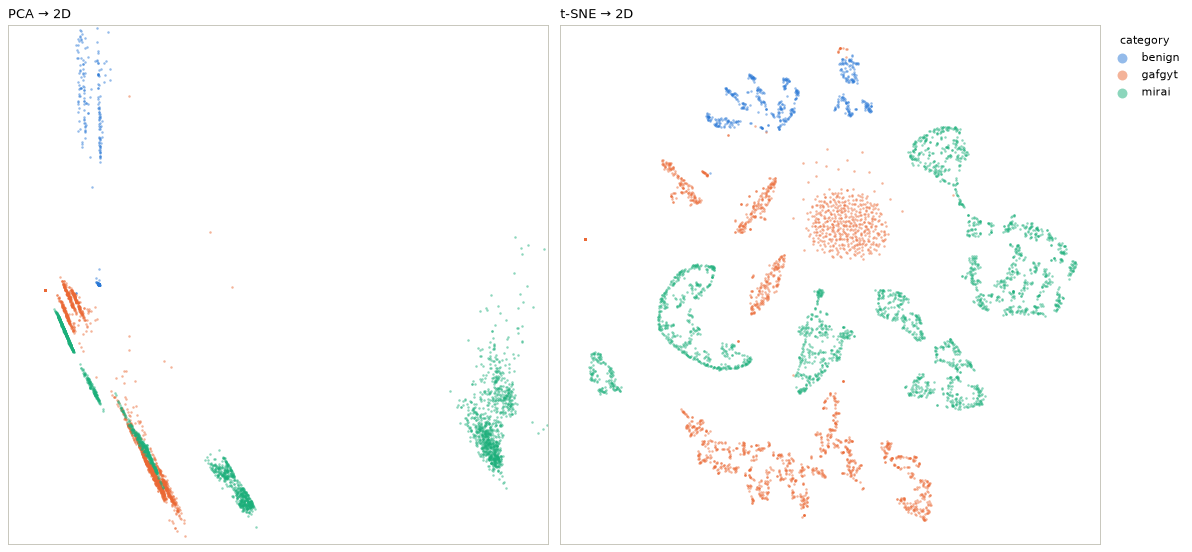

In [21]:
def scatter_by_category(ax, emb, data, title, clip_outliers=False):
    for cat, color in COLORS.items():
        m = (data['category'] == cat).values
        ax.scatter(emb[m, 0], emb[m, 1], s=5, color=color, alpha=0.5, linewidths=0, label=cat)
    if clip_outliers:
        # кілька екстремальних точок стискають картинку, тому показуємо 1-99 перцентилі
        lo, hi = np.percentile(emb, [1, 99], axis=0)
        pad = (hi - lo) * 0.08
        ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0])
        ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    ax.set_title(title, loc='left', fontsize=12)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color('#c3c2b7')


fig, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=80)
scatter_by_category(axes[0], pca_2d, vis_df, 'PCA → 2D', clip_outliers=True)
scatter_by_category(axes[1], tsne_2d, vis_df, 't-SNE → 2D')
axes[1].legend(title='category', markerscale=4, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

На цьому графіку колір позначає ботнет (3 кольори), бо 11 кольорів на одній хмарі точок не розрізнити. Щоб побачити кожен клас окремо, нижче намалюємо ту саму картинку t-SNE 11 разів. Усі точки будуть сірими, а точки одного класу кольоровими.

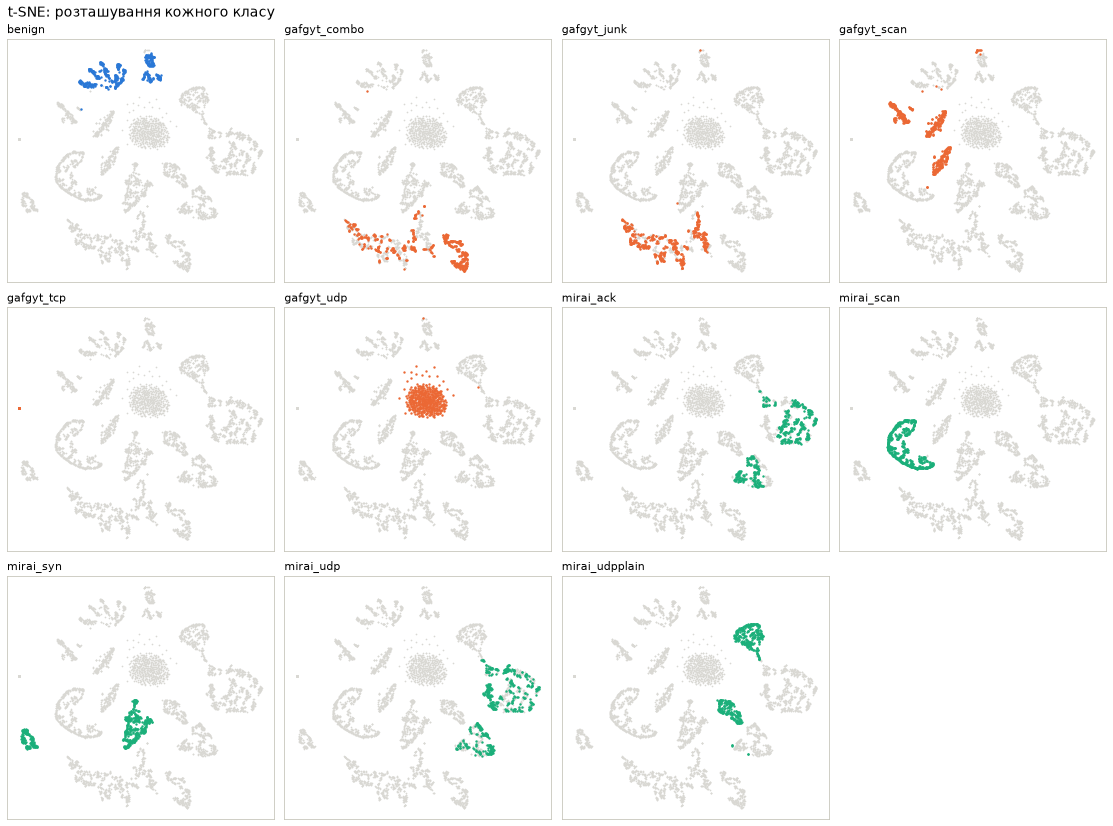

In [22]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12), dpi=70)
for ax, label in zip(axes.flat, le.classes_):
    m = (vis_df['label'] == label).values
    color = COLORS[label.split('_')[0]]
    ax.scatter(tsne_2d[~m, 0], tsne_2d[~m, 1], s=3, color='#d9d8d3', linewidths=0)
    ax.scatter(tsne_2d[m, 0], tsne_2d[m, 1], s=6, color=color, linewidths=0)
    ax.set_title(label, loc='left', fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color('#c3c2b7')
axes.flat[-1].axis('off')
fig.suptitle('t-SNE: розташування кожного класу', x=0.01, ha='left', fontsize=14)
plt.tight_layout()
plt.show()

Класи утворюють **окремі острови**. Більшість класів займає власні ділянки, які майже не перетинаються з іншими. Це наочно пояснює, чому в Lab 1 класифікатори отримали точність понад 99 %, адже класи в просторі ознак справді добре розділені. Нормальний трафік (benign) лежить окремо від усіх атак, тому відрізнити атаку від норми найлегше.

Один клас може складатися з кількох островів. benign, mirai_syn, mirai_udp і mirai_udpplain розпадаються на дві групи, а gafgyt_scan на три. Отже, всередині класу є різні режими трафіку. Це знадобиться в завданні 2, де кластери не зобов'язані збігатися з класами.

Схожі пари лежать поруч і перемішуються. mirai_ack і mirai_udp займають ті самі два острови, а gafgyt_combo і gafgyt_junk ділять одну спільну область унизу. Саме ці пари класифікатори плутали в Lab 1.

gafgyt_tcp стиснувся в одну точку ліворуч (на маленькому графіку її ледве видно), а gafgyt_udp утворив рівну круглу хмару без внутрішньої структури. Майже всі записи цих двох атак однакові, 1 пакет на 60 байт, і t-SNE стягує однакові точки разом. Розвело ці два класи лише те, що їхні записи мають різні часові мітки в HH_jit (артефакт з Lab 1).

PCA у 2D показує менше, бо дві компоненти зберігають лише 47 % дисперсії, і більшість класів накладаються одна на одну. Окремо видно лише benign (угорі ліворуч) і атаки mirai з великими пакетами (ack, udp, udpplain, хмара праворуч), а решта атак злипається в смуги ліворуч унизу. Тому для візуалізації складних даних використовують t-SNE, а PCA для стиснення ознак перед моделлю.

## 2) Кластерний аналіз

### Що таке K-Means

Кластеризація належить до навчання без учителя. Алгоритм отримує лише ознаки, без label, і сам групує схожі записи.

**K-Means** ділить дані на k груп так, щоб записи всередині групи були якомога ближче до центру своєї групи (центроїда). Спочатку він випадково обирає k початкових центроїдів, потім відносить кожен запис до найближчого центроїда і переносить кожен центроїд у середнє своїх записів. Останні два кроки повторюються, поки центроїди не перестануть зміщуватися.

Результат залежить від початкових центроїдів, тому n_init=10 запускає алгоритм 10 разів з різних стартів і залишає найкращий результат.


### Вибір класів для аналізу

11 класів дають таблицю порівняння 11 × k, яку важко читати, тому, як дозволяє завдання, залишаємо **3 класи**. Це benign (нормальний трафік, базовий стан пристрою), gafgyt_udp (найбільший клас атак ботнету Gafgyt у повному датасеті, 105 874 записи) і mirai_udp (найбільший клас атак ботнету Mirai, 237 665 записів).

Тобто беремо по одному класу на кожен стан пристрою, а саме норму, зараження Gafgyt і зараження Mirai. Обидві атаки є UDP-флудом, тобто атакою одного типу, тож ми перевіряємо, чи розділяє K-Means саме ботнети, а не лише «тихий» трафік від «шумного».

Мітки класів не використовуються під час кластеризації, лише після неї для порівняння.

In [23]:
CLUSTER_CLASSES = ['benign', 'gafgyt_udp', 'mirai_udp']

clu_df = df_bal[df_bal['label'].isin(CLUSTER_CLASSES)].reset_index(drop=True)
print(f'Записів для кластеризації: {len(clu_df):,}')
print(clu_df['label'].value_counts().to_string())

Записів для кластеризації: 9,000
label
benign        3000
gafgyt_udp    3000
mirai_udp     3000


### Підготовка ознак для K-Means

K-Means працює з відстанями, тому до ознак він вимогливіший за класифікатори з Lab 1. Ознаки готуємо у три кроки.

Спочатку логарифмуємо їх. Значення ознак розкидані на багато порядків, від 0 до 10¹⁷ (Lab 1), і без логарифма відстань визначали б кілька ознак з гігантськими числами. Логарифм переводить значення в «порядки величини», а sign і модуль потрібні, бо covariance і pcc бувають від'ємними.

Далі масштабуємо через StandardScaler, щоб усі ознаки мали однаковий вплив на відстань.

Наостанок **обрізаємо викиди до ±5 стандартних відхилень**. K-Means мінімізує суму квадратів відстаней, тому кілька екстремальних записів перетягують на себе цілий центроїд. Без обрізання він виділяє окремі кластери з 1-2 точок, що ми перевіримо нижче.

In [24]:
from sklearn.cluster import KMeans

X_log = np.sign(clu_df[feature_cols]) * np.log1p(np.abs(clu_df[feature_cols]))
X_log_scaled = StandardScaler().fit_transform(X_log)

outliers = np.abs(X_log_scaled) > 5
print(f'Значень за межами ±5σ: {outliers.mean():.2%} (є хоча б одне в {outliers.any(axis=1).sum()} записах з {len(clu_df):,})')

X_clu = np.clip(X_log_scaled, -5, 5)

# перевірка: що буде без обрізання викидів
sizes_raw = np.bincount(KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X_log_scaled))
sizes_clip = np.bincount(KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X_clu))
print('Розміри 5 кластерів без обрізання:', sorted(sizes_raw.tolist()))
print('Розміри 5 кластерів з обрізанням: ', sorted(sizes_clip.tolist()))

Значень за межами ±5σ: 0.12% (є хоча б одне в 392 записах з 9,000)
Розміри 5 кластерів без обрізання: [1, 1034, 1968, 2995, 3002]
Розміри 5 кластерів з обрізанням:  [1033, 1139, 1859, 1968, 3001]


Обрізання зачіпає лише близько 0.1 % значень, але без нього K-Means витрачає один з кластерів на одиничний викид. Далі працюємо з X_clu.

### Вибір кількості кластерів методом Elbow і Silhouette Score

У методі Elbow рахуємо inertia для k від 1 до 10. Зі зростанням k inertia завжди падає, бо більше центроїдів означає менші відстані до них. Шукаємо точку, після якої додатковий кластер дає вже малий виграш.

Silhouette порівнює кожну пару записів (9 000² пар), тому рахуємо його на випадковій підвибірці з 5 000 записів (sample_size=5000).

In [25]:
from sklearn.metrics import silhouette_score

k_values = range(1, 11)
inertia, silhouette = {}, {}
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    inertia[k] = km.inertia_
    if k > 1:
        silhouette[k] = silhouette_score(X_clu, km.labels_, sample_size=5000, random_state=42)

choice = pd.DataFrame({'inertia': pd.Series(inertia), 'silhouette': pd.Series(silhouette)})
choice['падіння inertia, %'] = (1 - choice['inertia'] / choice['inertia'].shift(1)) * 100
choice.round(3)

,inertia,silhouette,"падіння inertia, %"
1,745116.322,NaN,NaN
2,321134.912,0.614,56.901
3,203304.524,0.625,36.692
4,124182.441,0.694,38.918
5,80578.518,0.784,35.113
6,65678.027,0.802,18.492
7,54010.299,0.786,17.765
8,46867.813,0.791,13.224
9,40897.438,0.797,12.739
10,36720.118,0.799,10.214


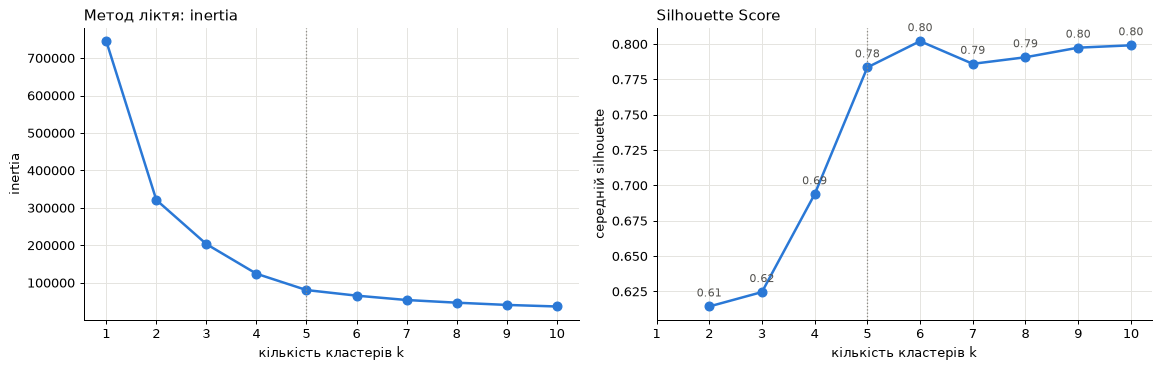

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), dpi=90)

axes[0].plot(choice.index, choice['inertia'], color='#2a78d6', marker='o', markersize=7, linewidth=2)
axes[0].set_title('Метод ліктя: inertia', loc='left', fontsize=12)
axes[0].set_ylabel('inertia')

sil = choice['silhouette'].dropna()
axes[1].plot(sil.index, sil.values, color='#2a78d6', marker='o', markersize=7, linewidth=2)
for k, s in sil.items():
    axes[1].annotate(f'{s:.2f}', (k, s), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, color='#52514e')
axes[1].set_title('Silhouette Score', loc='left', fontsize=12)
axes[1].set_ylabel('середній silhouette')

for ax in axes:
    ax.set_xlabel('кількість кластерів k')
    ax.set_xticks(list(k_values))
    clean_axes(ax)
    ax.axvline(5, color='#898781', linestyle=':', linewidth=1)
plt.tight_layout()
plt.show()

За методом ліктя до k = 5 кожен новий кластер зменшує inertia на 35-57 %, а після k = 5 лише на 18 % і менше, тож лікоть припадає на k = 5.

Silhouette різко росте до k = 5 (з 0.61 до 0.78), а далі майже не змінюється (0.78-0.80). Максимум 0.80 при k = 6 лише на 0.02 більший, тобто додаткові кластери тільки дрібнять уже наявні групи.

Обидва методи вказують на **k = 5**, це найменша кількість кластерів, після якої якість суттєво не росте. Отже, природних груп у даних 5, хоча класів лише 3. Подивимось, з чого складаються ці групи.

### K-Means з k = 5 і порівняння з класами

Таблиця спряженості (pd.crosstab) показує, скільки записів кожного класу потрапило в кожен кластер.

Для порівняння кластерів з класами використаємо три метрики. ARI (Adjusted Rand Index) показує, наскільки два розбиття збігаються. 1 означає повний збіг, а значення близько 0 означає, що розбиття не краще за випадкове, причому ARI не залежить від номерів кластерів. Homogeneity (однорідність) дорівнює 1, якщо кожен кластер містить записи лише одного класу. Completeness (повнота) дорівнює 1, якщо всі записи кожного класу потрапили в один кластер.

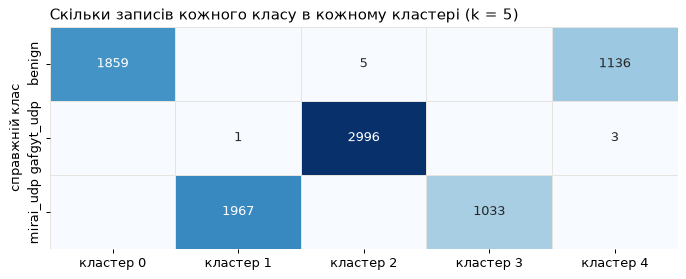

ARI:          0.748
Homogeneity:  0.993
Completeness: 0.711


In [27]:
from sklearn.metrics import adjusted_rand_score, homogeneity_score, completeness_score

K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_clu)
clu_df['cluster'] = kmeans.labels_

ct = pd.crosstab(clu_df['label'], clu_df['cluster'])
ct.columns = [f'кластер {c}' for c in ct.columns]

fig, ax = plt.subplots(figsize=(9, 3.2), dpi=90)
sns.heatmap(ct, annot=np.where(ct > 0, ct.astype(str), ''), fmt='', cmap='Blues', cbar=False,
            linewidths=0.5, linecolor='#e5e4e0', ax=ax)
ax.set_title('Скільки записів кожного класу в кожному кластері (k = 5)', loc='left', fontsize=12)
ax.set_xlabel('')
ax.set_ylabel('справжній клас')
plt.show()

print(f'ARI:          {adjusted_rand_score(clu_df["label"], clu_df["cluster"]):.3f}')
print(f'Homogeneity:  {homogeneity_score(clu_df["label"], clu_df["cluster"]):.3f}')
print(f'Completeness: {completeness_score(clu_df["label"], clu_df["cluster"]):.3f}')

Кожен кластер майже повністю складається з одного класу (homogeneity ≈ 0.99). K-Means жодного разу не змішав нормальний трафік з атакою і не змішав два ботнети.

Але класи розпалися на частини (completeness ≈ 0.71). gafgyt_udp утворив один кластер, а benign і mirai_udp по два кластери кожен. Тому **ARI ≈ 0.75**, розбиття схоже на справжні класи, але не збігається з ними, бо кластерів більше, ніж класів.

Щоб зрозуміти, чому benign і mirai_udp розпалися надвоє, подивимось на медіани кількох ознак у кожній групі.

In [28]:
key_features = ['H_L0.01_weight', 'H_L0.01_mean', 'HH_L0.01_weight', 'HH_L0.01_mean', 'HH_L0.01_std', 'HH_L0.01_radius']

big_groups = clu_df.groupby(['label', 'cluster']).filter(lambda g: len(g) > 50)   # без одиничних записів
big_groups.groupby(['label', 'cluster'])[key_features].median().round(1)

H_L0.01_weight  H_L0.01_mean  HH_L0.01_weight  HH_L0.01_mean  HH_L0.01_std  HH_L0.01_radius
label      cluster                                                                                             
benign     0                  30.0          92.7              4.2          102.0           0.0              0.0
           4                  30.8          92.2             11.7           76.8          18.8            505.8
gafgyt_udp 2                   1.0          60.0              1.0           60.0           0.0              0.0
mirai_udp  1               54413.2         383.1          35574.2          554.0           4.6             21.3
           3               55179.0         383.1              1.0           60.0           0.0              0.0

Ознаки H описують увесь трафік пристрою, а ознаки HH трафік у каналі між пристроєм і конкретним хостом. weight означає кількість пакетів, mean середній розмір пакета, а std і radius показують, наскільки різні розміри пакетів у каналі.

mirai_udp має **два режими атаки**. Загальна картина в обох групах однакова, десятки тисяч пакетів приблизно по 383 байти (ознаки H). Але в одній групі флуд іде стабільним каналом до одного хоста (HH_L0.01_weight ≈ 35 тис., пакети приблизно по 554 байти), а в іншій статистика каналу виглядає як перший пакет нового з'єднання (HH_L0.01_weight = 1, 60 байт). Схоже, що в цей час атака йшла на різні адреси або порти, і канал щоразу був новим.

benign має два режими нормальної роботи. В одній групі пакети в каналі однакового розміру (std = 0, radius = 0), тобто це одноманітний службовий обмін. В іншій розміри пакетів різні (std ≈ 19, radius ≈ 500), що відповідає активнішому обміну даними.

gafgyt_udp утворив один кластер, бо майже всі його записи однакові, 1 пакет на 60 байт без жодних варіацій.

Тобто K-Means знайшов реальні підтипи трафіку, а не помилився.

### Для порівняння k = 3, стільки ж, скільки класів

Що буде, якщо примусово задати стільки кластерів, скільки класів?

In [29]:
labels_k3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_clu)

ct3 = pd.crosstab(clu_df['label'], labels_k3)
ct3.columns = [f'кластер {c}' for c in ct3.columns]
print(ct3.to_string())
print(f'\nARI при k = 3: {adjusted_rand_score(clu_df["label"], labels_k3):.3f}')

            кластер 0  кластер 1  кластер 2
label                                      
benign              0       3000          0
gafgyt_udp          0       2999          1
mirai_udp        1033          0       1967

ARI при k = 3: 0.457


При k = 3 кластери теж не збігаються з класами. benign і gafgyt_udp об'єдналися в один кластер, а mirai_udp розділився на два кластери за своїми режимами атаки.

Причина в тому, що з погляду відстаней два режими mirai_udp відрізняються сильніше, ніж benign від gafgyt_udp. І норма, і gafgyt_udp є «тихим» трафіком (одиниці або десятки пакетів у вікні) на тлі десятків тисяч пакетів у Mirai. K-Means мінімізує inertia, тому йому вигідніше розрізати найбільшу і найрізноманітнішу групу. Підлаштовувати кластери під наш поділ на класи він не намагається.

### Візуалізація кластерів у 2D (t-SNE)

Будуємо t-SNE для тих самих 9 000 записів і тих самих підготовлених ознак X_clu. Ліворуч точки пофарбовані за кластерами K-Means, праворуч за справжніми класами. Номери кластерів підписані біля їхніх центрів. Кольори кластерів навмисно інші, ніж кольори класів, бо номер кластера ні з яким класом не пов'язаний.


t-SNE рахувався 20 с


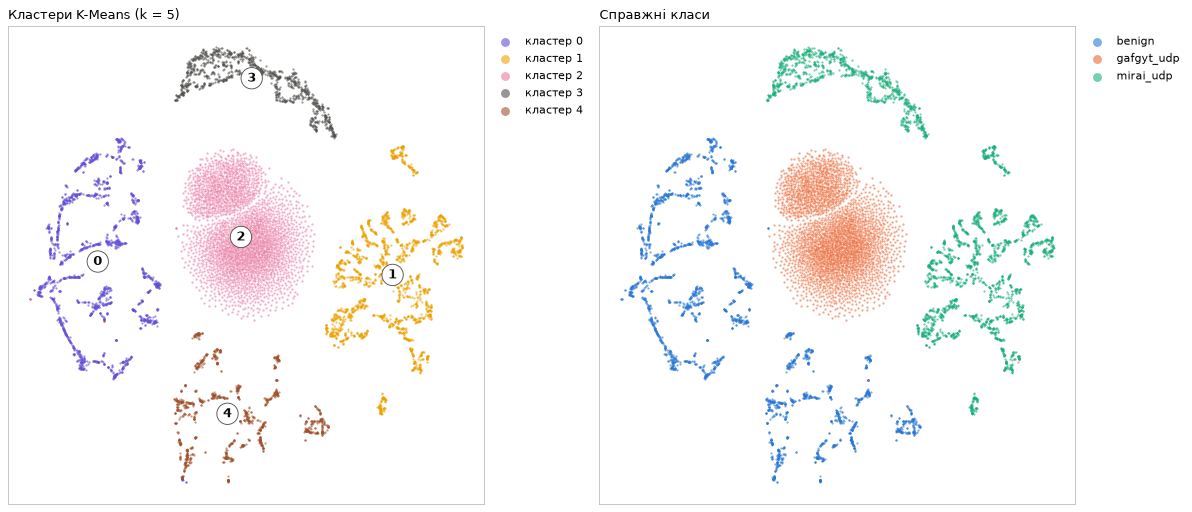

In [30]:
t0 = time.perf_counter()
clu_2d = TSNE(n_components=2, perplexity=30, init='pca', random_state=42).fit_transform(X_clu)
print(f't-SNE рахувався {time.perf_counter() - t0:.0f} с')

CLUSTER_COLORS = ['#6250d6', '#eda100', '#e87ba4', '#52514e', '#a0522d']   # не збігаються з кольорами класів

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), dpi=80)

for c in range(K):
    m = (clu_df['cluster'] == c).values
    axes[0].scatter(clu_2d[m, 0], clu_2d[m, 1], s=4, color=CLUSTER_COLORS[c], alpha=0.6, linewidths=0, label=f'кластер {c}')
    cx, cy = np.median(clu_2d[m], axis=0)
    axes[0].annotate(str(c), (cx, cy), ha='center', va='center', fontsize=12, fontweight='bold', color='#0b0b0b',
                     bbox=dict(boxstyle='circle,pad=0.3', fc='white', ec='#52514e', lw=0.8))
axes[0].set_title(f'Кластери K-Means (k = {K})', loc='left', fontsize=12)
axes[0].legend(markerscale=4, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))

for label in CLUSTER_CLASSES:
    m = (clu_df['label'] == label).values
    axes[1].scatter(clu_2d[m, 0], clu_2d[m, 1], s=4, color=COLORS[label.split('_')[0]], alpha=0.6, linewidths=0, label=label)
axes[1].set_title('Справжні класи', loc='left', fontsize=12)
axes[1].legend(markerscale=4, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color('#c3c2b7')
plt.tight_layout()
plt.show()

Праворуч кожен клас займає власну ділянку і не змішується з іншими, тобто класи в даних справді розділені. Ліворуч межі кластерів проходять усередині класів. mirai_udp і benign поділені на дві частини, які й на t-SNE лежать окремими групами, а gafgyt_udp утворює один щільний кластер. При цьому межі кластерів ніде не перетинають межі класів, тож **кластери тут є «підкласами»**.

### Висновок до кластерного аналізу

Знайдена кластерна структура відповідає реальним класам **лише частково**.

Метод ліктя і Silhouette Score вказали на k = 5, а не на 3, тобто природних груп у даних більше, ніж класів.

Кластери вийшли «чистими», кожен складається з одного класу (homogeneity ≈ 0.99). K-Means без жодних міток відокремив нормальний трафік від атак і атаки Gafgyt від атак Mirai, хоча обидві є UDP-флудом.

Самі класи неоднорідні, benign і mirai_udp складаються з двох режимів кожен (completeness ≈ 0.71). Це реальні підтипи трафіку, тобто різні режими нормальної роботи дзвінка і два режими атаки Mirai.

При k = 3 відповідність гірша (ARI ≈ 0.46), бо K-Means об'єднав два «тихі» класи і розрізав найрізноманітніший. Отже, кількість кластерів, рівна кількості класів, не гарантує, що кластери стануть класами.

Кластер є групою схожих записів, а клас міткою, яку поставила людина. Тут структура даних дрібніша за мітки, і кожен клас складається з одного або кількох кластерів. На практиці це означає, що навіть без міток можна виявити незвичний (атакувальний) трафік, а кластеризація ще й показує, що всередині класів є різні режими.

## 3) Обробка та класифікація текстових даних

### Датасет YouTube Spam Collection

N-BaIoT не містить текстів, тому для цього завдання беремо окремий датасет з UCI, [YouTube Spam Collection](https://archive.ics.uci.edu/dataset/380/youtube+spam+collection). Він містить 1 956 справжніх коментарів англійською з п'яти дуже популярних кліпів (Psy - Gangnam Style, Katy Perry, LMFAO - Party Rock Anthem, Eminem - Love the Way You Lie, Shakira - Waka Waka), зібраних у 2015 році. Дані лежать у 5 CSV-файлах, по одному на кліп, з колонками COMMENT_ID, AUTHOR, DATE, CONTENT (текст коментаря) і CLASS (1 означає спам, 0 звичайний коментар).

Датасет пов'язаний з кібербезпекою, бо спам у коментарях є не лише рекламою каналів. Через нього поширюють шахрайські схеми на зразок «заробітку вдома», фішингові й шкідливі посилання, тому **автоматичний фільтр таких коментарів є типовою задачею захисту платформ**.

### Автоматичне завантаження датасету

Код нижче сам завантажує і розпаковує датасет у папку youtube_spam поруч із ноутбуком. Спочатку він перевіряє, чи файли вже є. Якщо всі 5 CSV на місці, нічого не завантажується, тож повторний запуск ноутбука не качає дані щоразу. Якщо файлів немає, код завантажує zip-архів з UCI (urllib.request.urlretrieve), розпаковує його (zipfile) і видаляє архів. Обидві бібліотеки стандартні, тому встановлювати нічого не треба. Якщо UCI недоступний, ті самі 5 CSV завантажуються з копії на GitHub.

CSV шукаємо через rglob, тобто в папці й усіх підпапках, бо всередині архіву файли можуть лежати у вкладеній папці. Службові файли macOS пропускаємо.

In [31]:
import urllib.request
import zipfile

YT_DIR = Path('youtube_spam')
UCI_URL = 'https://archive.ics.uci.edu/static/public/380/youtube+spam+collection.zip'
MIRROR_URL = 'https://raw.githubusercontent.com/sahilbhange/YouTube-comments-Spam-Detector/master/'
YT_FILES = ['Youtube01-Psy.csv', 'Youtube02-KatyPerry.csv', 'Youtube03-LMFAO.csv',
            'Youtube04-Eminem.csv', 'Youtube05-Shakira.csv']


def find_csv(folder):
    # CSV датасету в папці та підпапках (по одному на назву), без службових файлів macOS
    files = {}
    for f in sorted(folder.rglob('Youtube0*.csv')):
        if '__MACOSX' not in f.parts:
            files.setdefault(f.name, f)
    return list(files.values())


def download_youtube_spam(folder):
    folder.mkdir(exist_ok=True)
    zip_path = folder / 'youtube_spam_collection.zip'
    try:
        print('Завантажую архів з UCI...')
        urllib.request.urlretrieve(UCI_URL, zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(folder)
        print('Архів розпаковано.')
    except Exception as error:
        print(f'Не вдалося завантажити з UCI: {error}')
    finally:
        zip_path.unlink(missing_ok=True)   # архів більше не потрібен

    if len(find_csv(folder)) < len(YT_FILES):
        print('Завантажую CSV-файли з копії на GitHub...')
        for name in YT_FILES:
            urllib.request.urlretrieve(MIRROR_URL + name, folder / name)


if len(find_csv(YT_DIR)) < len(YT_FILES):
    download_youtube_spam(YT_DIR)
else:
    print('Датасет уже завантажено, пропускаю завантаження.')

csv_files = find_csv(YT_DIR)
print('Файли датасету:', [f.name for f in csv_files])

Завантажую архів з UCI...
Архів розпаковано.
Файли датасету: ['Youtube01-Psy.csv', 'Youtube02-KatyPerry.csv', 'Youtube03-LMFAO.csv', 'Youtube04-Eminem.csv', 'Youtube05-Shakira.csv']


In [32]:
parts = []
for f in csv_files:
    part = pd.read_csv(f)
    part['VIDEO'] = f.stem.split('-')[1]     # Youtube01-Psy -> Psy
    parts.append(part)
yt = pd.concat(parts, ignore_index=True)

print('Розмір:', yt.shape)
yt.head()

Розмір: (1956, 6)


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1,Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Psy


У кожному файлі однакові колонки, тому склеюємо їх в одну таблицю через pd.concat. Колонку VIDEO додаємо самі, щоб знати, з якого кліпу коментар, це знадобиться наприкінці. Для класифікації потрібні лише CONTENT (текст) і CLASS (мітка).

In [33]:
print('Спам / не спам за кліпами:')
print(pd.crosstab(yt['VIDEO'], yt['CLASS'].map({0: 'ham', 1: 'spam'}), margins=True, margins_name='усього').to_string())

print(f'\nКоментарів з однаковим текстом: {yt["CONTENT"].duplicated().sum()}')
print(yt.loc[yt['CONTENT'].duplicated(), 'CONTENT'].value_counts().head(3).to_string())

Спам / не спам за кліпами:
CLASS      ham  spam  усього
VIDEO                       
Eminem     203   245     448
KatyPerry  175   175     350
LMFAO      202   236     438
Psy        175   175     350
Shakira    196   174     370
усього     951  1005    1956

Коментарів з однаковим текстом: 196
CONTENT
Check out this video on YouTube:﻿                         96
Check out this playlist on YouTube:﻿                      20
Check Out The New Hot Video By Dante B Called Riled Up     5


196 коментарів повторюють текст іншого коментаря. Найчастіше це одна й та сама спам-фраза від різних акаунтів, наприклад «Check out this video on YouTube». **Дублікати видаляємо** з тієї ж причини, що й у Lab 1. Якщо одна копія потрапить у train, а інша в test, оцінка якості буде завищеною. COMMENT_ID у копій різний, тому шукаємо дублікати саме за текстом (subset='CONTENT').

In [34]:
yt = yt.drop_duplicates(subset='CONTENT', ignore_index=True)
yt['label'] = yt['CLASS'].map({0: 'ham', 1: 'spam'})
print(f'Після видалення дублікатів: {len(yt):,} коментарів')
print(yt['label'].value_counts().to_string())

has_link = yt['CONTENT'].str.contains(r'http|www\.|\.com', case=False)
pd.DataFrame({
    'медіанна довжина, символів': yt.groupby('label')['CONTENT'].apply(lambda s: s.str.len().median()),
    'частка з посиланням': has_link.groupby(yt['label']).mean().round(3),
})

Після видалення дублікатів: 1,760 коментарів
label
ham     919
spam    841


,"медіанна довжина, символів",частка з посиланням
label,,
ham,35.0,0.011
spam,78.0,0.272


Класи майже збалансовані (близько 48 % спаму), тож accuracy тут інформативна, але окремо все одно дивимося на precision і recall класу spam.

Спам удвічі довший і **приблизно в 25 разів частіше містить посилання** (27 % проти 1.1 %).

У текстах є сміття, яке треба почистити. Це HTML-теги (&lt;br /&gt;, &lt;a href=...&gt;), HTML-коди (&amp;#39; замість апострофа, &amp;amp;) і невидимий символ U+FEFF у кінці більшості коментарів.

### Передобробка текстів

Функція clean_text виконує кілька кроків. Спочатку html.unescape перетворює HTML-коди (&amp;#39;, &amp;amp;, &amp;quot;) на звичайні символи, після чого прибираємо невидимий символ U+FEFF і HTML-теги (&lt;br /&gt;, &lt;a ...&gt;). Потім усе переводимо в нижній регістр через lower(), щоб Check, CHECK і check стали одним словом.

Посилання (http..., www..., щось.com, /watch?v=...) замінюємо словом url. Сама адреса неважлива, але факт посилання є сильною ознакою спаму. Апострофи прибираємо (don't стає dont, Psy’s стає psys), щоб скорочення не розпадалися на шматки.

Далі **пунктуацію, цифри й інші символи замінюємо пробілами** і залишаємо лише латинські літери. Стандартного string.punctuation тут замало, бо в коментарях є «криві» лапки, смайлики на зразок ♥ і навіть корейські літери (강남스타일).

Наостанок видаляємо **стоп-слова**, тобто службові слова (the, and, you, this...), які трапляються всюди й нічого не кажуть про клас. Беремо вбудований у sklearn список ENGLISH_STOP_WORDS (318 слів) і додаємо кілька інтернет-скорочень, які є тими самими стоп-словами (u означає you, ur означає your, im означає I'm). Також відкидаємо «слова» з однієї літери.

In [35]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

EXTRA_STOP_WORDS = {'u', 'ur', 'im', 'dont', 'ill', 'll', 've', 're', 'didnt', 'doesnt', 'cant', 'wont',
                    'ive', 'youre', 'thats', 'whats'}
STOP_WORDS = ENGLISH_STOP_WORDS | EXTRA_STOP_WORDS
URL_PATTERN = re.compile(r'https?://\S+|www\.\S+|\b[\w-]+\.(?:com|net|org|tk|pl|ly|be|ru|us|info|co|me|tv)\b\S*|/watch\?v=\S+')


def clean_text(text):
    text = html.unescape(text).replace('﻿', ' ')     # HTML-коди і невидимий символ
    text = re.sub(r'<[^>]+>', ' ', text).lower()            # HTML-теги, нижній регістр
    text = URL_PATTERN.sub(' url ', text)                   # посилання -> url
    text = re.sub(r"['’]", '', text)                        # don't -> dont
    text = re.sub(r'[^a-z]+', ' ', text)                    # пунктуація, цифри, смайлики, інші алфавіти
    words = [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]
    return ' '.join(words)


yt['clean'] = yt['CONTENT'].map(clean_text)

empty = yt['clean'] == ''
print(f'Порожніх після очищення: {empty.sum()} (лише смайлики, цифри або стоп-слова), видаляємо їх')
yt = yt[~empty].reset_index(drop=True)
print(f'Залишилось коментарів: {len(yt):,}')

pd.set_option('display.max_colwidth', 110)
yt.sample(8, random_state=3)[['label', 'CONTENT', 'clean']]

Порожніх після очищення: 16 (лише смайлики, цифри або стоп-слова), видаляємо їх
Залишилось коментарів: 1,744


,label,CONTENT,clean
1412,ham,That guy charley of lost TV show﻿,guy charley lost tv
1612,spam,Subscribe to my channel :) &lt;3,subscribe channel
745,ham,Good﻿,good
199,spam,https://www.tsu.co/Aseris get money here !﻿,url money
863,ham,In my head this is like 2 years ago.. Time FLIES﻿,head like years ago time flies
181,ham,OPPA &lt;3﻿,oppa
1473,ham,Waka waka﻿,waka waka
324,ham,Haha its so funny to see the salt of westerners that top views of youtube goes to video they dont even un...,haha funny salt westerners views youtube goes video understand salt


### Характерні слова і словосполучення класів (WordCloud)

WordCloud (хмара слів) малює слова розміром, пропорційним їхній частоті, тобто що частіше слово трапляється в класі, то більшим воно намальоване.

Частоти рахуємо через CountVectorizer. З ngram_range=(1, 1) він рахує окремі слова, а з ngram_range=(2, 2) **біграми**, тобто пари слів, що стоять поруч (словосполучення). Хмари будуємо окремо для ham і spam, щоб порівняти класи.

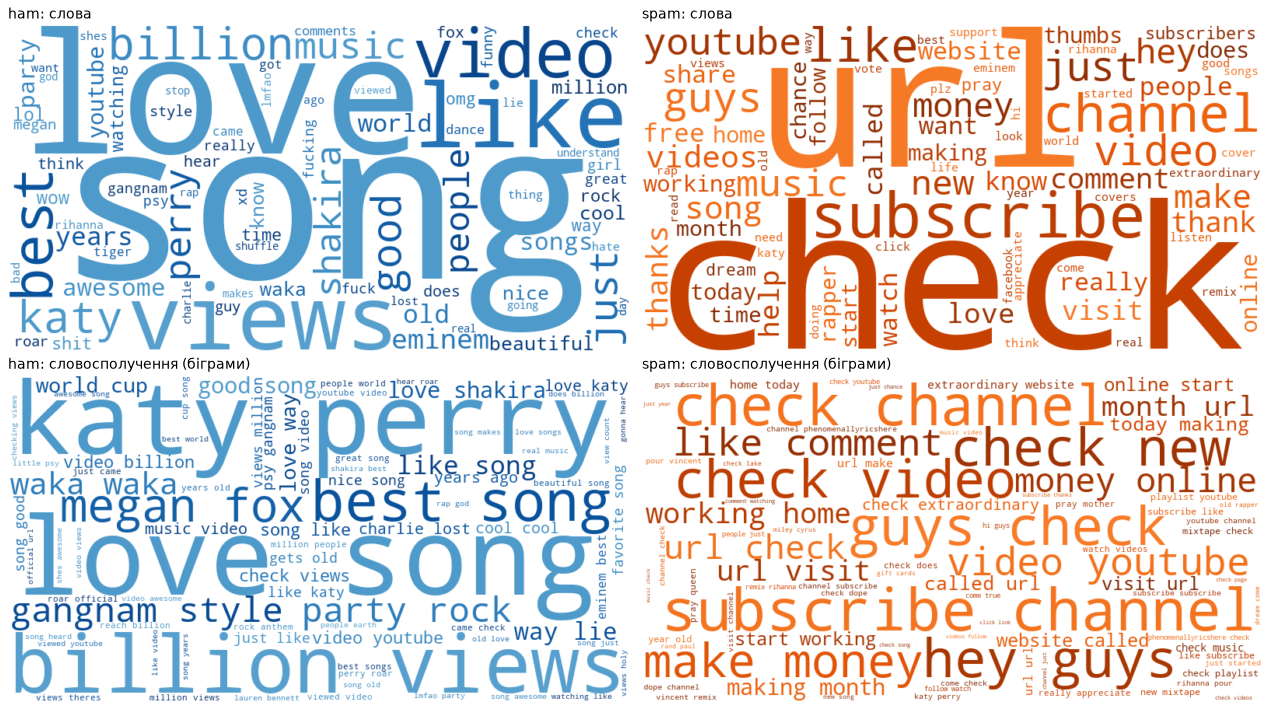

In [37]:
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud


def ngram_counts(texts, ngram_range):
    vectorizer = CountVectorizer(ngram_range=ngram_range)
    counts = vectorizer.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=vectorizer.get_feature_names_out()).sort_values(ascending=False)


def class_colors(cmap_name):
    # кольори слів лише з темної половини палітри, щоб світлі слова не губилися на білому тлі
    cmap = plt.get_cmap(cmap_name)
    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        r, g, b, _ = cmap(0.55 + 0.45 * random_state.random())
        return f'rgb({int(r * 255)}, {int(g * 255)}, {int(b * 255)})'
    return color_func


CLASS_CMAPS = {'ham': 'Blues', 'spam': 'Oranges'}

fig, axes = plt.subplots(2, 2, figsize=(16, 9), dpi=80)
for row, (ngrams, kind) in enumerate([((1, 1), 'слова'), ((2, 2), 'словосполучення (біграми)')]):
    for col, label in enumerate(['ham', 'spam']):
        freq = ngram_counts(yt.loc[yt['label'] == label, 'clean'], ngrams)
        cloud = WordCloud(width=800, height=420, background_color='white', max_words=80,
                          color_func=class_colors(CLASS_CMAPS[label]), random_state=42)
        cloud.generate_from_frequencies(freq.head(300).to_dict())
        axes[row, col].imshow(cloud, interpolation='bilinear')
        axes[row, col].set_title(f'{label}: {kind}', loc='left', fontsize=13)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

In [38]:
top = {}
for label in ['ham', 'spam']:
    texts = yt.loc[yt['label'] == label, 'clean']
    words = ngram_counts(texts, (1, 1)).head(12)
    bigrams = ngram_counts(texts, (2, 2)).head(12)
    top[f'{label}: слово'] = [f'{w} ({n})' for w, n in words.items()]
    top[f'{label}: біграма'] = [f'{w} ({n})' for w, n in bigrams.items()]
pd.DataFrame(top)

,ham: слово,ham: біграма,spam: слово,spam: біграма
0,song (214),love song (42),check (382),subscribe channel (45)
1,love (139),katy perry (36),url (327),check channel (42)
2,views (87),billion views (31),subscribe (216),guys check (39)
3,like (87),best song (22),channel (186),hey guys (38)
4,video (84),megan fox (14),like (149),check video (37)
5,best (56),gangnam style (13),video (117),check new (37)
6,billion (56),party rock (13),guys (114),make money (33)
7,katy (54),waka waka (10),just (108),video youtube (32)
8,good (48),like song (9),youtube (97),like comment (31)
9,just (44),way lie (8),music (92),money online (29)


Spam складається з самореклами і шахрайства. Найчастіші слова тут check, url, subscribe, channel, guys, money, website, visit, free, share. Біграми показують типові шаблони, як-от subscribe channel, check channel, check video, hey guys, like comment («лайкни коментар»). Є й ціла шахрайська схема з багатьох однакових коментарів, у якій ідуть make money, money online, working home, extraordinary website і website called url («заробляй вдома, заходь на сайт...»). **Спам майже завжди щось просить**, перейти, підписатися або лайкнути.

Ham є реакцією на сам кліп. Тут переважають song, love, like, views, best, billion, beautiful та імена виконавців (katy, perry, shakira, eminem). Серед біграм є love song, best song, katy perry і назви пісень (gangnam style, party rock, waka waka, love way, way lie). Біграма billion views з'являється тому, що Gangnam Style першим на YouTube набрав мільярд переглядів, і в коментарях це активно обговорювали, а megan fox є акторкою з кліпу Eminem.

Деякі слова є в обох класах (like, video, music, youtube, song), бо всі коментарі стосуються музичних відео. Тому важливі не лише окремі слова, а й їхні поєднання, і саме для цього в TF-IDF додаємо біграми.

### Векторизація TF-IDF

Модель не вміє працювати з текстом напряму, їй потрібні числа. **TF-IDF** перетворює кожен коментар на вектор, де кожен елемент відповідає одному слову або біграмі зі словника.

Параметр ngram_range=(1, 2) додає в словник і слова, і біграми, тож модель бачить фрази на зразок subscribe channel чи make money. min_df=2 відкидає слова, які трапилися менше ніж у 2 коментарях, і так прибирає одноразові опечатки, ніки та випадкові слова. sublinear_tf=True замінює tf на 1 + log(tf), щоб слово, повторене 5 разів, не важило в 5 разів більше.

Спочатку ділимо дані на train і test (80/20, зі стратифікацією). Векторизатор навчається **лише на train**, словник і idf беруться з train, а test тільки перетворюється.

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

y_yt = yt['CLASS']   # 1 = spam, 0 = ham
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    yt['clean'], y_yt, test_size=0.2, stratify=y_yt, random_state=42)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
A_train = tfidf.fit_transform(Xt_train)
A_test = tfidf.transform(Xt_test)

print(f'Train: {A_train.shape[0]:,} коментарів, test: {A_test.shape[0]:,}')
print(f'Розмір словника (ознак): {A_train.shape[1]:,}')
print(f'Ненульових елементів у матриці train: {A_train.nnz / (A_train.shape[0] * A_train.shape[1]):.2%}')

i = int(np.flatnonzero((yt_train.values == 1) & (A_train.getnnz(axis=1) >= 10))[0])   # перший спам-коментар з ≥ 10 ознаками
row = A_train[i].toarray().ravel()
print(f'\nПриклад: "{Xt_train.iloc[i]}"')
print(pd.Series(row, index=tfidf.get_feature_names_out())[row > 0].sort_values(ascending=False).head(12).round(3).to_string())

Train: 1,395 коментарів, test: 349
Розмір словника (ознак): 1,615
Ненульових елементів у матриці train: 0.44%

Приклад: "new makeup transformation integrated look like feature available ver know look like install update version makeup transformation url visit google play"
makeup         0.522
look           0.383
google play    0.321
version        0.298
play           0.267
google         0.259
like           0.237
url visit      0.234
visit          0.207
know           0.202
new            0.196
url            0.132


Матриця вийшла розрідженою. Кожен коментар містить лише кілька слів зі словника, тому понад 99 % елементів дорівнюють нулю. sklearn зберігає такі матриці у форматі scipy.sparse, де записані лише ненульові значення.

У прикладі видно, що рідкісніші слова й біграми отримують більшу вагу, а слова, які є в багатьох коментарях, меншу.

### Навчання моделей

Порівнюємо дві класичні моделі для текстів.

Multinomial Naive Bayes є імовірнісною моделлю. Вона рахує, наскільки часто кожне слово трапляється в кожному класі, і за формулою Байєса обирає клас з найбільшою ймовірністю. «Наївною» її називають тому, що вона вважає слова незалежними одне від одного. Модель дуже швидка і є стандартним baseline для текстів.

LinearSVC є лінійним SVM (як у Lab 1, але з лінійним ядром). Він шукає гіперплощину з максимальним зазором між класами. Для текстів з тисячами розріджених ознак лінійне ядро є стандартним вибором, бо класи і так добре розділяються лінійно, а RBF-ядро було б повільним і зайвим.

Модель обираємо **крос-валідацією на train** (5 фолдів, метрика macro F1). Векторизатор і модель обгорнуті в Pipeline, тож TF-IDF у кожному фолді навчається заново лише на його train-частині.

In [40]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

text_models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'LinearSVC': LinearSVC(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, clf in text_models.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ('clf', clf)])
    scores = cross_val_score(pipe, Xt_train, yt_train, cv=cv, scoring='f1_macro')
    cv_rows.append({'модель': name, 'macro F1 (CV), середнє': scores.mean(), 'розкид (std)': scores.std()})

pd.DataFrame(cv_rows).set_index('модель').round(4)

,"macro F1 (CV), середнє",розкид (std)
модель,,
Multinomial Naive Bayes,0.9209,0.0081
LinearSVC,0.9460,0.0102


LinearSVC кращий на крос-валідації, тому він буде основною моделлю. Навчаємо обидві моделі на всьому train і оцінюємо на test.

In [41]:
for name, clf in text_models.items():
    clf.fit(A_train, yt_train)
    yt_pred = clf.predict(A_test)
    print(f'===== {name} =====')
    print(classification_report(yt_test, yt_pred, target_names=['ham', 'spam'], digits=4))

===== Multinomial Naive Bayes =====
              precision    recall  f1-score   support

         ham     0.8995    0.9392    0.9189       181
        spam     0.9313    0.8869    0.9085       168

    accuracy                         0.9140       349
   macro avg     0.9154    0.9131    0.9137       349
weighted avg     0.9148    0.9140    0.9139       349

===== LinearSVC =====
              precision    recall  f1-score   support

         ham     0.9247    0.9503    0.9373       181
        spam     0.9448    0.9167    0.9305       168

    accuracy                         0.9341       349
   macro avg     0.9348    0.9335    0.9339       349
weighted avg     0.9344    0.9341    0.9340       349



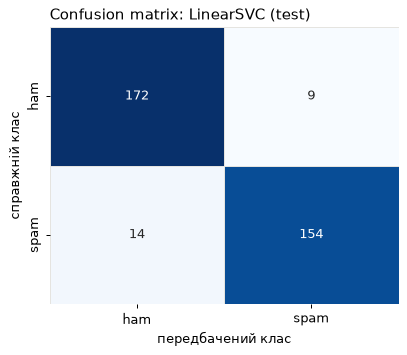

Accuracy моделі «завжди найчастіший клас»: 0.5186
Accuracy LinearSVC:                        0.9341


In [42]:
svc = text_models['LinearSVC']
yt_pred = svc.predict(A_test)
cm = confusion_matrix(yt_test, yt_pred)

fig, ax = plt.subplots(figsize=(5, 4), dpi=90)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=0.5, linecolor='#e5e4e0',
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'], ax=ax)
ax.set_title('Confusion matrix: LinearSVC (test)', loc='left', fontsize=12)
ax.set_xlabel('передбачений клас')
ax.set_ylabel('справжній клас')
plt.show()

majority = max(yt_test.mean(), 1 - yt_test.mean())
print(f'Accuracy моделі «завжди найчастіший клас»: {majority:.4f}')
print(f'Accuracy LinearSVC:                        {accuracy_score(yt_test, yt_pred):.4f}')

Класи збалансовані, і модель, яка завжди відповідає найчастішим класом, мала б лише 0.52, тому **accuracy 0.934** тут чесна метрика.

Для класу spam precision ≈ 0.94, тобто з того, що модель назвала спамом, 94 % справді спам. Recall ≈ 0.92, тобто модель знаходить 92 % спаму. F1 ≈ 0.93.

Помилок 23 з 349. Дев'ять звичайних коментарів помилково названо спамом, а 14 спам-коментарів пропущено. Naive Bayes гірший (accuracy 0.914), бо пропускає більше спаму (recall 0.89).

Точність нижча, ніж 99 % у Lab 1, бо коментарі дуже короткі (медіана звичайного 35 символів) і написані тією самою «ютубною» мовою. Межа між звичайним коментарем і самопіаром іноді розмита навіть для людини.

### Що модель вважає ознаками спаму

LinearSVC є лінійною моделлю, тож кожне слово має коефіцієнт (вагу). Додатна вага тягне коментар до spam, від'ємна до ham. Подивимось на слова з найбільшими вагами.

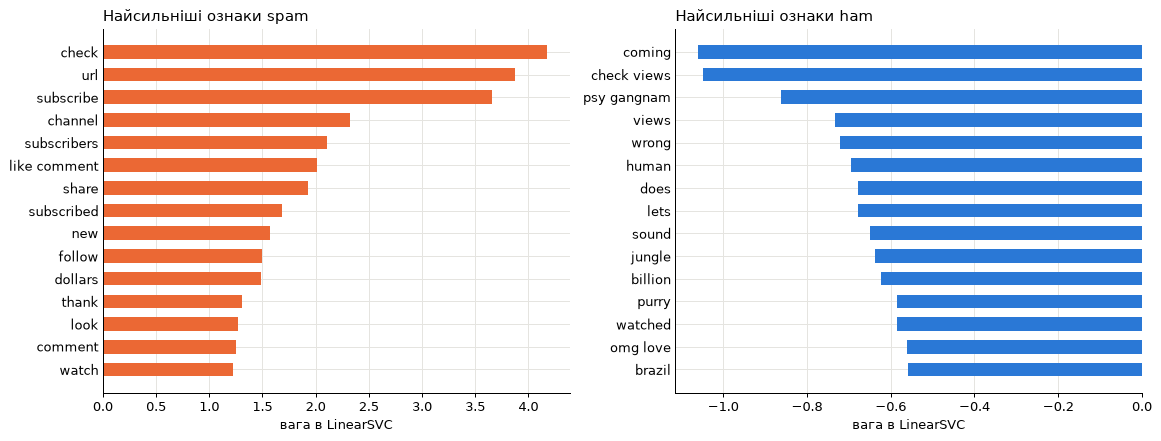

In [43]:
coef = pd.Series(svc.coef_.ravel(), index=tfidf.get_feature_names_out())
top_spam = coef.sort_values(ascending=False).head(15)[::-1]
top_ham = coef.sort_values().head(15)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=90)
axes[0].barh(top_spam.index, top_spam.values, height=0.6, color='#eb6834')
axes[0].set_title('Найсильніші ознаки spam', loc='left', fontsize=12)
axes[1].barh(top_ham.index, top_ham.values, height=0.6, color='#2a78d6')
axes[1].set_title('Найсильніші ознаки ham', loc='left', fontsize=12)
for ax in axes:
    ax.set_xlabel('вага в LinearSVC')
    clean_axes(ax)
    ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()

Ваги моделі збігаються з хмарами слів. Найсильніші ознаки спаму є закликами до дії (check, url, subscribe, channel, subscribers, like comment, share, follow, watch), а також dollars, тобто обіцянками заробітку. Ознаки звичайних коментарів стосуються обговорення самого кліпу (views, billion, psy gangnam, watched, omg love).

Цікавий приклад дає слово check. Окремо воно є найсильнішою ознакою спаму («check out my channel»), а біграма check views має одну з найбільших «звичайних» ваг. Це фраза «came here to check the views», тобто людина прийшла подивитися на лічильник переглядів. **Модель з біграмами розрізняє ці два значення**, а модель лише з окремими словами не змогла б.

Подивимось, на чому модель помиляється.

In [44]:
readable = yt.loc[Xt_test.index, 'CONTENT'].map(html.unescape).str.replace('﻿', '').str.replace(r'<[^>]+>', ' ', regex=True)
test_df = pd.DataFrame({'текст': readable,
                        'справжній': yt_test.map({0: 'ham', 1: 'spam'}),
                        'передбачений': pd.Series(yt_pred, index=Xt_test.index).map({0: 'ham', 1: 'spam'})})
errors = test_df[test_df['справжній'] != test_df['передбачений']]
print(f'Помилок: {len(errors)} з {len(test_df)}')
errors.sort_values('справжній')

Помилок: 23 з 349


,текст,справжній,передбачений
1291,Hello I'm from Bulgaria,ham,spam
850,Thumbs up if you're watching in 2015,ham,spam
1481,"To help shakira become the first female to hit 1billiom views, I've decided to watch this Video at least o...",ham,spam
131,Justin bieber = gay,ham,spam
61,The first comment is chuck norrus ovbiously :D,ham,spam
217,"Hello all 29.24% earth population of the world, hope your having a great day :)",ham,spam
28,I dont even watch it anymore i just come here to check on 2 Billion or not,ham,spam
686,This song means so much to me thank you soooooooooooooooooooooooooooooooooooooooo much:-) Xxx,ham,spam
1260,Hello. İ am from Azerbaijan,ham,spam
628,The Perry you're doing a good job good job I love all of their videos and by the way can you please descr...,spam,ham


Серед 9 звичайних коментарів, названих спамом, є привітання і звертання до всіх («Hello I'm from Bulgaria», «Thumbs up if you're watching in 2015», «hope your having a great day»), які за формою схожі на звернення спамерів до аудиторії. Є й коментарі зі «спамовими» словами в іншому значенні, наприклад «i just come here to check on 2 Billion».

Серед 14 пропущених спам-коментарів трапляються нетипові теми, наприклад молитва, розбита на частини («Part 2. Holy Mary, pray for us...»), короткі прохання без посилань («like please», «Subscribe and u are gonna hear me roar») і реклама, замаскована під звичайний коментар («This song can beat PSY - Gangnam Style!», «CHECK OUT Eminem - Rap God LYRIC VIDEO»). В останніх випадках «звичайні» слова (eminem, rap, song) переважили.

Частину таких коментарів важко однозначно класифікувати навіть людині.

### Чи працює фільтр на коментарях до нового кліпу

Звичайне випадкове розбиття змішує коментарі з усіх п'яти кліпів, тож модель бачила на train коментарі до тих самих відео, що й у test. Перевіримо складніший сценарій, у якому **навчаємо на чотирьох кліпах і перевіряємо на п'ятому**, якого модель не бачила. Так фільтр працював би на новому відео.

In [45]:
rows = []
for video in sorted(yt['VIDEO'].unique()):
    is_test = yt['VIDEO'] == video
    pipe = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ('clf', LinearSVC())])
    pipe.fit(yt.loc[~is_test, 'clean'], yt.loc[~is_test, 'CLASS'])
    pred = pipe.predict(yt.loc[is_test, 'clean'])
    rows.append({'кліп для перевірки': video, 'коментарів': int(is_test.sum()),
                 'accuracy': accuracy_score(yt.loc[is_test, 'CLASS'], pred),
                 'F1 (spam)': f1_score(yt.loc[is_test, 'CLASS'], pred)})

pd.DataFrame(rows).set_index('кліп для перевірки').round(4)

,коментарів,accuracy,F1 (spam)
кліп для перевірки,,,
Eminem,399,0.9499,0.9502
KatyPerry,344,0.9448,0.9459
LMFAO,337,0.9525,0.9424
Psy,346,0.9075,0.9149
Shakira,318,0.9308,0.9160


На новому кліпі фільтр працює майже так само добре, **accuracy 0.91-0.95** залежно від кліпу (на випадковому розбитті 0.934). Спам-шаблони («check my channel», «subscribe», посилання) однакові під усіма відео, тому модель, навчена на одних кліпах, переноситься на інші. Найгірший результат на Psy (0.91), але й там різниця невелика.

Це важлива перевірка. У Lab 1 ми бачили, що випадкове розбиття може завищувати оцінку, а тут перевірка на «чужому» кліпі показала, що оцінка чесна.

### Висновки до класифікації текстів

Передобробка (HTML-коди й теги, заміна посилань на url, нижній регістр, лише латинські літери, видалення стоп-слів) залишає змістовні слова. Без неї модель бачила б сміття на кшталт HTML-кодів, тегів і невидимих символів.

WordCloud показав, що спам у коментарях складається з самореклами («check my channel», «subscribe») і шахрайства («make money online... working home»), а звичайні коментарі є реакціями на пісню й виконавця.

TF-IDF з біграмами (близько 1.6 тис. ознак) дає моделі не лише слова, а й фрази. Це важливо, бо check є ознакою спаму, а check views ознакою звичайного коментаря.

**LinearSVC дав accuracy ≈ 0.93 і F1 для спаму ≈ 0.93** (precision 0.94, recall 0.92) і виявився кращим за Naive Bayes. Класи збалансовані, тому accuracy тут чесна.

Фільтр переноситься на новий кліп (0.91-0.95), бо шаблони спаму однакові під різними відео. Пропускаються переважно нетипові теми та короткі прохання без посилань.

## Загальні висновки

PCA стиснув 115 сильно корельованих ознак N-BaIoT до 16 компонент зі збереженням 95 % дисперсії. kNN на них передбачає приблизно вдвічі швидше з невеликою втратою точності (з 0.9947 до 0.9838), а з 25 компонентами (99 %) майже без втрат. Для Random Forest PCA шкідливий, бо дерева втрачають прості пороги на початкових ознаках.

t-SNE показав, що класи трафіку утворюють окремі острови, і це пояснює високу точність класифікаторів з Lab 1. Схожі пари атак (combo і junk, ack і udp) лежать поруч, а деякі класи складаються з кількох груп.

K-Means без жодних міток відокремив нормальний трафік від атак і Gafgyt від Mirai. Але природних груп виявилося 5, а не 3, бо деякі класи складаються з кількох режимів трафіку. **Кластер не дорівнює класу.**

Класифікація коментарів YouTube через TF-IDF і LinearSVC дала accuracy ≈ 0.93 і F1 для спаму ≈ 0.93. Модель спирається на зрозумілі ознаки (заклики підписатися, посилання, обіцянки заробітку) і працює навіть на коментарях до кліпу, якого не бачила під час навчання.